# Fetal Gestational Age Prediction using Fetal Brain MRI

**Author**  **Name** : Komukama Anita  
**Registration No**. :2026/HD05/22742U  
**Student No**. :2600722742

**Complete ML workflow:** data preparation, patient-level data splitting, training and evaluation of five models, model comparison, Grad-CAM explainability, attention-weight analysis, and gestational-age error analysis.

**Dataset:** Stanford Digital Repository record `sf714wg0636`. This notebook expects the archive you have already downloaded. It does not download the 3.1 GB archive.

**Models**
1. Linear Regression (HOG + intensity histograms)
2. Random Forest Regression (HOG + intensity histograms)
3. Support Vector Regression, RBF (HOG + intensity histograms)
4. ResNet-18 (three-plane CNN)
5. Multi-Plane Attention-Guided ResNet-50 (reconstructed architecture)


## 1. Install dependencies

In [1]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn scikit-image openpyxl pillow tqdm shap lime torch torchvision

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
%pip install --upgrade ipywidgets jupyterlab_widgets widgetsnbextension tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 12.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 29.7 MB/s  0:00:00
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbextension 3.6.10
    Uninstalling widgetsnbextension-3.6.10:
      Successfully uninstalled widgetsnbextension-3.6.10
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.67.3
    Uninstalling tqdm-4.67.3:
      Successfully uninstalled tqdm-4.67.3
  Attempting uninstall: ipywidgets
    Found existing installation: ipywidgets 7.7.1
    Uninstalling ipywidgets-7.7.1:
      Successfully uninstalled ipywidgets-7.7.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [ipywidgets]


## 2. Imports and reproducibility

In [1]:
import os, re, json, hashlib, zipfile,ipywidgets ,tqdm , random, time, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from skimage.feature import hog
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## 3. Configure local archive and experiment
Edit `ZIP_PATH` to the location of your downloaded `fetal-brain.zip`. If already extracted, set `EXTRACT_DIR` to that directory.

In [5]:

from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

# Main project folder in Google Drive
PROJECT_DIR = Path("/content/drive/MyDrive/fetal-gestational-age")

# Dataset ZIP file
ZIP_PATH = PROJECT_DIR / "fetal-brain.zip"

# Folder where dataset contents will be extracted
EXTRACT_DIR = PROJECT_DIR / "extracted_complete"

# Automatically locate Excel workbook after extraction
LABELS_PATH = None

IMAGE_SIZE = 224

BATCH_SIZE = 16 if DEVICE.type == "cuda" else 4

EPOCHS_RESNET18 = 12
EPOCHS_ATTENTION = 15

PATIENCE = 4
LEARNING_RATE = 1e-4

RESULTS = PROJECT_DIR / "results_fetal_ga"
RESULTS.mkdir(exist_ok=True, parents=True)

print("Project folder:", PROJECT_DIR)
print("Project folder exists:", PROJECT_DIR.exists())

print("ZIP file exists:", ZIP_PATH.exists())
print("ZIP path:", ZIP_PATH)

print("Extraction folder:", EXTRACT_DIR)

print("Results folder:", RESULTS)


Mounted at /content/drive
Project folder: /content/drive/MyDrive/fetal-gestational-age
Project folder exists: True
ZIP file exists: True
ZIP path: /content/drive/MyDrive/fetal-gestational-age/fetal-brain.zip
Extraction folder: /content/drive/MyDrive/fetal-gestational-age/extracted_complete
Results folder: /content/drive/MyDrive/fetal-gestational-age/results_fetal_ga


In [6]:
if ZIP_PATH.exists():
    print("SUCCESS: fetal-brain.zip found!")
else:
    print("ERROR: ZIP file not found. Check the notebook working directory.")

SUCCESS: fetal-brain.zip found!


## 4. Verify archive and extract
The published Stanford archive checksum is checked before extraction. Extraction requires approximately 3.1 GB plus working space.

In [7]:
EXPECTED_MD5="b01047641a7e32feebce048df86f88da"
def md5_file(p):
    h=hashlib.md5()
    with open(p,"rb") as f:
        for b in iter(lambda:f.read(8*1024*1024),b""): h.update(b)
    return h.hexdigest()
if not EXTRACT_DIR.exists() or not any(EXTRACT_DIR.iterdir()):
    if not ZIP_PATH.exists(): raise FileNotFoundError(f"Set ZIP_PATH to your downloaded archive. Not found: {ZIP_PATH}")
    digest=md5_file(ZIP_PATH); print("MD5:",digest)
    if digest!=EXPECTED_MD5: raise ValueError("MD5 mismatch; verify the downloaded archive.")
    EXTRACT_DIR.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(EXTRACT_DIR)
else: print("Using existing extraction:",EXTRACT_DIR)

Using existing extraction: /content/drive/MyDrive/fetal-gestational-age/extracted_complete


## 5. Locate and inspect labels workbook

In [8]:
if LABELS_PATH is None:
    xs=list(EXTRACT_DIR.rglob("labels.xlsx"))
    if not xs: xs=list(EXTRACT_DIR.rglob("*.xlsx"))
    if len(xs)!=1:
        print("Workbook candidates:",xs)
        raise RuntimeError("Set LABELS_PATH explicitly if zero or multiple workbooks were found.")
    LABELS_PATH=xs[0]
xls=pd.ExcelFile(LABELS_PATH)
print("Workbook:",LABELS_PATH,"Sheets:",xls.sheet_names)
labels_raw=pd.read_excel(LABELS_PATH,sheet_name=xls.sheet_names[0])
print(labels_raw.shape,labels_raw.columns.tolist())
display(labels_raw.head())

Workbook: /content/drive/MyDrive/fetal-gestational-age/extracted_complete/images/labels.xlsx Sheets: ['Sheet1']
(741, 9) ['patient_id', 'ga_days', 'ga_wks', 'ax_series', 'ax_midslice', 'cor_series', 'cor_midslice', 'sag_series', 'sag_midslice']


,patient_id,ga_days,ga_wks,ax_series,ax_midslice,cor_series,cor_midslice,sag_series,sag_midslice
0,1,154,22.000000,599,IM-0599-0010.jpg,597,IM-0597-0012.jpg,598,IM-0598-0008.jpg
1,2,226,32.285714,1209,IM-1209-0009.jpg,1211,IM-1211-0012.jpg,1210,IM-1210-0011.jpg
2,3,233,33.285714,1796,IM-1796-0013.jpg,1797,IM-1797-0015.jpg,1795,IM-1795-0014.jpg
3,4,165,23.571429,2114,IM-2114-0011.jpg,2113,IM-2113-0009.jpg,2115,IM-2115-0011.jpg
4,5,237,33.857143,2421,IM-2421-0013.jpg,2419,IM-2419-0016.jpg,2420,IM-2420-0013.jpg


## 6. Map label columns
Review the columns printed above. Set exact column names below. The target is gestational age in days; patient ID is required for leakage-safe splitting.

In [9]:
def detect(cols, patterns):
    for c in cols:
        s = re.sub(r"[^a-z0-9]+", " ", str(c).lower()).strip()
        if any(re.search(p, s) for p in patterns):
            return c
    return None


# 1. Detect patient and gestational-age columns
PATIENT_COL = detect(
    labels_raw.columns,
    [r"patient.*id", r"subject.*id", r"^id$"]
)

GA_DAYS_COL = "ga_days" if "ga_days" in labels_raw.columns else detect(
    labels_raw.columns,
    [r"gestational.*day", r"ga.*day", r"^days$"]
)

GA_WEEKS_COL = "ga_wks" if "ga_wks" in labels_raw.columns else detect(
    labels_raw.columns,
    [r"gestational.*week", r"ga.*week", r"^weeks$"]
)


# 2. Map MRI middle-slice filename columns
AXIAL_COL = "ax_midslice"
CORONAL_COL = "cor_midslice"
SAGITTAL_COL = "sag_midslice"


# 3. Validate required columns
if PATIENT_COL is None:
    raise ValueError("Patient ID column was not detected.")

if GA_DAYS_COL is None and GA_WEEKS_COL is None:
    raise ValueError("No gestational-age column was detected.")

for col in [AXIAL_COL, CORONAL_COL, SAGITTAL_COL]:
    if col not in labels_raw.columns:
        raise ValueError(f"Column not found: {col}")


# 4. Display detected column mapping
print("Patient column:", PATIENT_COL)
print("Gestational age (days):", GA_DAYS_COL)
print("Gestational age (weeks):", GA_WEEKS_COL)
print("Axial image:", AXIAL_COL)
print("Coronal image:", CORONAL_COL)
print("Sagittal image:", SAGITTAL_COL)


# 5. Prepare dataset
data = labels_raw.copy()

data["patient_id"] = data[PATIENT_COL].astype(str).str.strip()

data["ga_days"] = (
    pd.to_numeric(data[GA_DAYS_COL], errors="coerce")
    if GA_DAYS_COL else
    pd.to_numeric(data[GA_WEEKS_COL], errors="coerce") * 7
)

data["ga_weeks"] = (
    pd.to_numeric(data[GA_WEEKS_COL], errors="coerce")
    if GA_WEEKS_COL else
    data["ga_days"] / 7
)


# 6. Standardize MRI filenames
data["axial_file"] = data[AXIAL_COL].astype(str).str.strip()
data["coronal_file"] = data[CORONAL_COL].astype(str).str.strip()
data["sagittal_file"] = data[SAGITTAL_COL].astype(str).str.strip()


# 7. Remove records with missing essential values
data = data.dropna(
    subset=["patient_id", "ga_days", "ga_weeks"]
).copy()


# 8. Display prepared dataset
print("\nPrepared records:", len(data))

display(data[
    ["patient_id", "ga_days", "ga_weeks",
     "axial_file", "coronal_file", "sagittal_file"]
].head())


Patient column: patient_id
Gestational age (days): ga_days
Gestational age (weeks): ga_wks
Axial image: ax_midslice
Coronal image: cor_midslice
Sagittal image: sag_midslice

Prepared records: 741


,patient_id,ga_days,ga_weeks,axial_file,coronal_file,sagittal_file
0,1,154,22.000000,IM-0599-0010.jpg,IM-0597-0012.jpg,IM-0598-0008.jpg
1,2,226,32.285714,IM-1209-0009.jpg,IM-1211-0012.jpg,IM-1210-0011.jpg
2,3,233,33.285714,IM-1796-0013.jpg,IM-1797-0015.jpg,IM-1795-0014.jpg
3,4,165,23.571429,IM-2114-0011.jpg,IM-2113-0009.jpg,IM-2115-0011.jpg
4,5,237,33.857143,IM-2421-0013.jpg,IM-2419-0016.jpg,IM-2420-0013.jpg


## 7. Resolve image filenames and validate records
This matches workbook filenames to image basenames. If the workbook contains series numbers rather than filenames, adapt the resolver to the archive's folder/series naming scheme.

In [11]:
EXTS={".jpg",".jpeg",".png",".tif",".tiff"}
imgs=[p for p in EXTRACT_DIR.rglob("*") if p.is_file() and p.suffix.lower() in EXTS]
idx=defaultdict(list)
for p in imgs: idx[p.name.lower()].append(p)
def resolve(v):
    if pd.isna(v): return None
    hits=idx.get(Path(str(v).strip()).name.lower(),[])
    return hits[0] if len(hits)==1 else None
for c,o in [(AXIAL_COL,"axial_path"),(CORONAL_COL,"coronal_path"),(SAGITTAL_COL,"sagittal_path")]:
    data[o]=data[c].apply(resolve)
pathcols=["axial_path","coronal_path","sagittal_path"]
n0=len(data)
valid=data.dropna(subset=["patient_id","ga_days"]+pathcols).copy()
valid=valid[valid.ga_days.between(100,300)]
print("Images found:",len(imgs),"Rows before:",n0,"Valid:",len(valid),"Excluded:",n0-len(valid))
print("Unique patients:",valid.patient_id.nunique(),"GA days range:",valid.ga_days.min(),valid.ga_days.max())
if valid.empty: raise ValueError("No complete records; check filename mappings.")

Images found: 52906 Rows before: 741 Valid: 708 Excluded: 33
Unique patients: 708 GA days range: 133 273


## 8. Inspect example images and label distribution

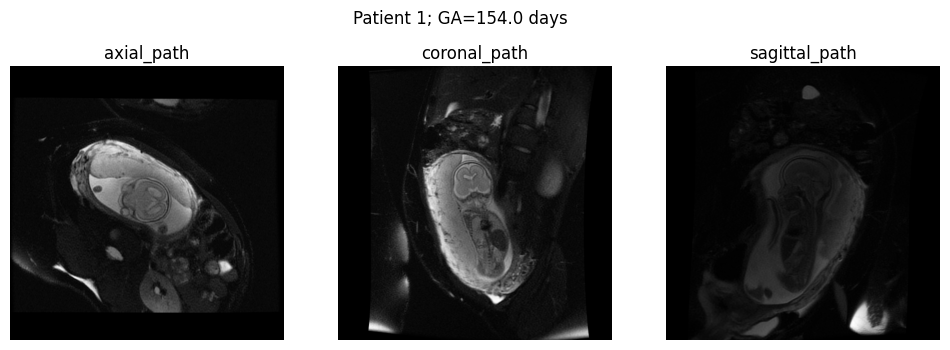

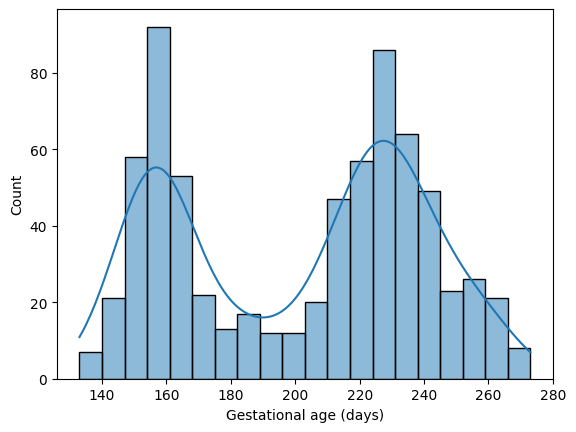

In [12]:
r=valid.iloc[0]
fig,axs=plt.subplots(1,3,figsize=(12,4))
for ax,c in zip(axs,pathcols):
    ax.imshow(Image.open(r[c]).convert("L"),cmap="gray"); ax.set_title(c); ax.axis("off")
plt.suptitle(f"Patient {r.patient_id}; GA={r.ga_days:.1f} days"); plt.show()
sns.histplot(valid.ga_days,bins=20,kde=True); plt.xlabel("Gestational age (days)"); plt.show()

## 9. Patient-level train/validation/test split
Approximately 70/15/15. All studies from a patient must remain in one partition.

In [13]:
g1=GroupShuffleSplit(n_splits=1,test_size=.30,random_state=SEED)
it,ivtmp=next(g1.split(valid,groups=valid.patient_id))
train_df=valid.iloc[it].reset_index(drop=True); tmp=valid.iloc[ivtmp].reset_index(drop=True)
g2=GroupShuffleSplit(n_splits=1,test_size=.50,random_state=SEED)
iv,ix=next(g2.split(tmp,groups=tmp.patient_id))
val_df=tmp.iloc[iv].reset_index(drop=True); test_df=tmp.iloc[ix].reset_index(drop=True)
ids=[set(d.patient_id) for d in [train_df,val_df,test_df]]
assert ids[0].isdisjoint(ids[1]) and ids[0].isdisjoint(ids[2]) and ids[1].isdisjoint(ids[2])
print("Rows:",*[len(d) for d in [train_df,val_df,test_df]])
print("Patients:",*[len(s) for s in ids],"No patient leakage.")

Rows: 495 106 107
Patients: 495 106 107 No patient leakage.


## 10. Classical image descriptors: HOG + intensity histogram

In [14]:
def gray_fixed(path,side=256):
    im=Image.open(path).convert("L"); im.thumbnail((side,side))
    a=np.asarray(im,dtype=np.float32)/255
    out=np.zeros((side,side),np.float32); out[:a.shape[0],:a.shape[1]]=a
    return out
def descriptor(path):
    a=gray_fixed(path)
    h=hog(a,orientations=8,pixels_per_cell=(16,16),cells_per_block=(2,2),feature_vector=True)
    hist,_=np.histogram(a,bins=32,range=(0,1))
    hist=hist.astype(np.float32)/max(hist.sum(),1)
    return np.r_[h.astype(np.float32),hist]
def features(frame):
    return np.vstack([np.concatenate([descriptor(row[c]) for c in pathcols]) for _,row in tqdm(frame.iterrows(),total=len(frame))])
Xtr=features(train_df); Xv=features(val_df); Xte=features(test_df)
ytr=train_df.ga_days.to_numpy(float); yv=val_df.ga_days.to_numpy(float); yte=test_df.ga_days.to_numpy(float)
print(Xtr.shape,Xv.shape,Xte.shape)

  0%|          | 0/495 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

  0%|          | 0/107 [00:00<?, ?it/s]

(495, 21696) (106, 21696) (107, 21696)


## 11. Metrics and classical models

In [15]:
def ccc(y,p):
    y=np.asarray(y); p=np.asarray(p); my,mp=y.mean(),p.mean()
    cov=np.mean((y-my)*(p-mp))
    den=np.var(y)+np.var(p)+(my-mp)**2
    return float(2*cov/den) if den else np.nan
def metrics(y,p):
    return {"MAE_days":mean_absolute_error(y,p),"RMSE_days":mean_squared_error(y,p)**.5,
            "R2":r2_score(y,p),"Lin_CCC":ccc(y,p),"MAE_weeks":mean_absolute_error(y,p)/7}
models_tab={
 "Linear Regression":Pipeline([("imp",SimpleImputer(strategy="median")),("scale",StandardScaler()),("model",LinearRegression())]),
 "Random Forest":Pipeline([("imp",SimpleImputer(strategy="median")),("model",RandomForestRegressor(n_estimators=300,min_samples_leaf=2,max_features="sqrt",random_state=SEED,n_jobs=-1))]),
 "SVR RBF":Pipeline([("imp",SimpleImputer(strategy="median")),("scale",StandardScaler()),("model",SVR(C=10,epsilon=2))])
}
val_preds={}
for name,m in models_tab.items():
    m.fit(Xtr,ytr); val_preds[name]=m.predict(Xv)
    print(name,metrics(yv,val_preds[name]))

Linear Regression {'MAE_days': 19.519834749367295, 'RMSE_days': 23.979699816932442, 'R2': 0.5607325140466985, 'Lin_CCC': 0.7254401835002936, 'MAE_weeks': 2.788547821338185}
Random Forest {'MAE_days': 25.475161803343404, 'RMSE_days': 28.736882268361438, 'R2': 0.36915760546554777, 'Lin_CCC': 0.4426802626742343, 'MAE_weeks': 3.6393088290490576}
SVR RBF {'MAE_days': 29.845836231254996, 'RMSE_days': 34.55157718540366, 'R2': 0.08803677201006, 'Lin_CCC': 0.24683477958172997, 'MAE_weeks': 4.263690890179285}


## 12. Three-plane CNN data pipeline
Each study is encoded as three channels (axial, coronal, sagittal). These are 2D middle slices, not full 3D volumes.

In [16]:
tfm=transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),transforms.ToTensor(),
                        transforms.Normalize([.5,.5,.5],[.5,.5,.5])])
class MRIDataset(Dataset):
    def __init__(self,df): self.df=df.reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self,i):
        row=self.df.iloc[i]; chans=[]
        for c in pathcols:
            im=Image.open(row[c]).convert("L").convert("RGB")
            chans.append(tfm(im)[0:1])
        return torch.cat(chans,0),torch.tensor(float(row.ga_days),dtype=torch.float32)
train_loader=DataLoader(MRIDataset(train_df),batch_size=BATCH_SIZE,shuffle=True,num_workers=0)
val_loader=DataLoader(MRIDataset(val_df),batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
test_loader=DataLoader(MRIDataset(test_df),batch_size=BATCH_SIZE,shuffle=False,num_workers=0)

## 13. ResNet-18 baseline and attention-guided ResNet-50

In [17]:
def resnet18():
    try: net=models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    except Exception as e: print("Pretrained weights unavailable:",e); net=models.resnet18(weights=None)
    net.conv1=nn.Conv2d(3,64,7,2,3,bias=False); net.fc=nn.Linear(net.fc.in_features,1)
    return net
class MultiPlaneAttentionResNet50(nn.Module):
    def __init__(self):
        super().__init__()
        try: b=models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        except Exception as e: print("Pretrained weights unavailable:",e); b=models.resnet50(weights=None)
        d=b.fc.in_features; self.encoder=nn.Sequential(*list(b.children())[:-1])
        self.attn=nn.Sequential(nn.Linear(d,256),nn.Tanh(),nn.Linear(256,1))
        self.head=nn.Sequential(nn.Linear(d,256),nn.ReLU(),nn.Dropout(.25),nn.Linear(256,1))
    def forward(self,x,return_attention=False):
        em=[]
        for j in range(3):
            z=x[:,j:j+1].repeat(1,3,1,1)
            em.append(self.encoder(z).flatten(1))
        stack=torch.stack(em,dim=1); w=torch.softmax(self.attn(stack).squeeze(-1),dim=1)
        pred=self.head((stack*w.unsqueeze(-1)).sum(1)).squeeze(1)
        return (pred,w) if return_attention else pred
m18=resnet18().to(DEVICE); matt=MultiPlaneAttentionResNet50().to(DEVICE)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 196MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 154MB/s]


## 14. CNN training utilities with validation early stopping

In [19]:

# ============================================================
# CNN TRAINING FUNCTIONS
# ============================================================

def predict_dl(model, loader):

    model.eval()
    ys, ps = [], []

    with torch.no_grad():
        for x, y in loader:

            x = x.to(DEVICE)

            z = model(x)

            if isinstance(z, tuple):
                z = z[0]

            z = z.reshape(-1)

            ys.extend(y.reshape(-1).cpu().numpy())
            ps.extend(z.cpu().numpy())

    return np.asarray(ys), np.asarray(ps)


def fit_cnn(model, epochs, name):

    model = model.to(DEVICE)

    opt = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt,
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )

    lossfn = nn.SmoothL1Loss()

    best = np.inf
    state = None
    stale = 0
    hist = []

    for ep in range(epochs):

        model.train()
        losses = []

        for x, y in tqdm(train_loader, leave=False):

            x = x.to(DEVICE)
            y = y.to(DEVICE).float().reshape(-1)

            opt.zero_grad(set_to_none=True)

            z = model(x)

            if isinstance(z, tuple):
                z = z[0]

            z = z.reshape(-1)

            loss = lossfn(z, y)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            opt.step()

            losses.append(loss.item())

        # Validation
        yy, pp = predict_dl(model, val_loader)

        vmae = mean_absolute_error(yy, pp)

        scheduler.step(vmae)

        hist.append({
            "epoch": ep + 1,
            "train_loss": np.mean(losses),
            "val_MAE": vmae,
            "learning_rate": opt.param_groups[0]["lr"]
        })

        print(
            name,
            ep + 1,
            "val MAE:",
            round(vmae, 3),
            "days | LR:",
            opt.param_groups[0]["lr"]
        )

        # Save best weights
        if vmae < best:

            best = vmae
            stale = 0

            state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        else:

            stale += 1

        if stale >= PATIENCE:
            print("Early stopping")
            break

    # Restore best model
    if state is not None:
        model.load_state_dict(state)

    torch.save(
        model.state_dict(),
        RESULTS / (name.lower().replace(" ", "_") + ".pt")
    )

    print(name, "best validation MAE:", round(best, 3), "days")

    return model, pd.DataFrame(hist)


# ============================================================
# TRAIN MODELS
# ============================================================

m18, h18 = fit_cnn(
    m18,
    EPOCHS_RESNET18,
    "ResNet18"
)

matt, ha = fit_cnn(
    matt,
    EPOCHS_ATTENTION,
    "Attention_ResNet50"
)


  0%|          | 0/31 [00:00<?, ?it/s]

ResNet18 1 val MAE: 165.79 days | LR: 0.0001


  0%|          | 0/31 [00:00<?, ?it/s]

ResNet18 2 val MAE: 163.268 days | LR: 0.0001


  0%|          | 0/31 [00:00<?, ?it/s]

ResNet18 3 val MAE: 159.368 days | LR: 0.0001


... (40 outputs left out)

  0%|          | 0/31 [00:00<?, ?it/s]

Attention_ResNet50 12 val MAE: 11.341 days | LR: 5e-05


  0%|          | 0/31 [00:00<?, ?it/s]

Attention_ResNet50 13 val MAE: 11.101 days | LR: 5e-05
Early stopping
Attention_ResNet50 best validation MAE: 10.256 days


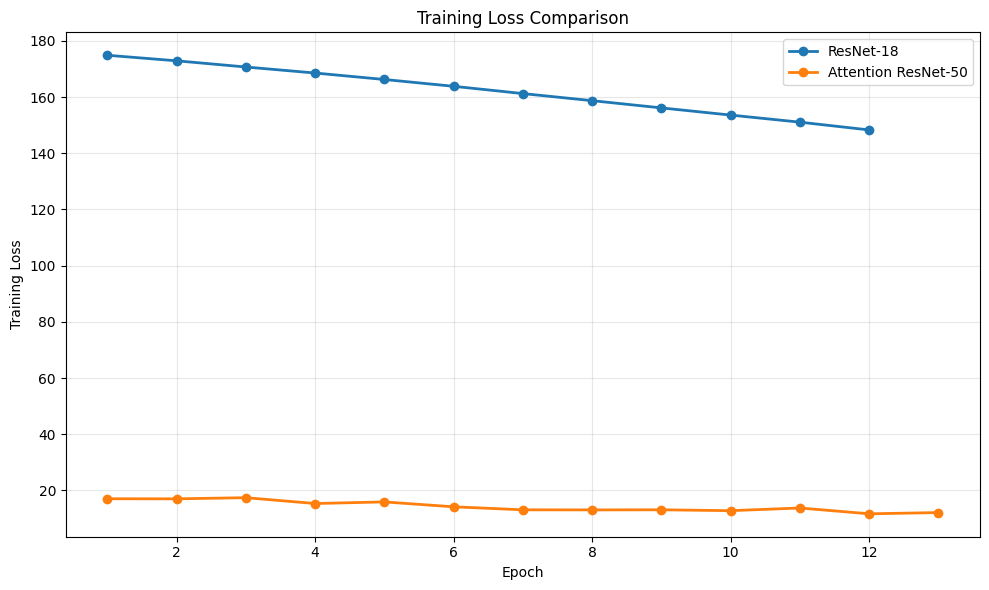

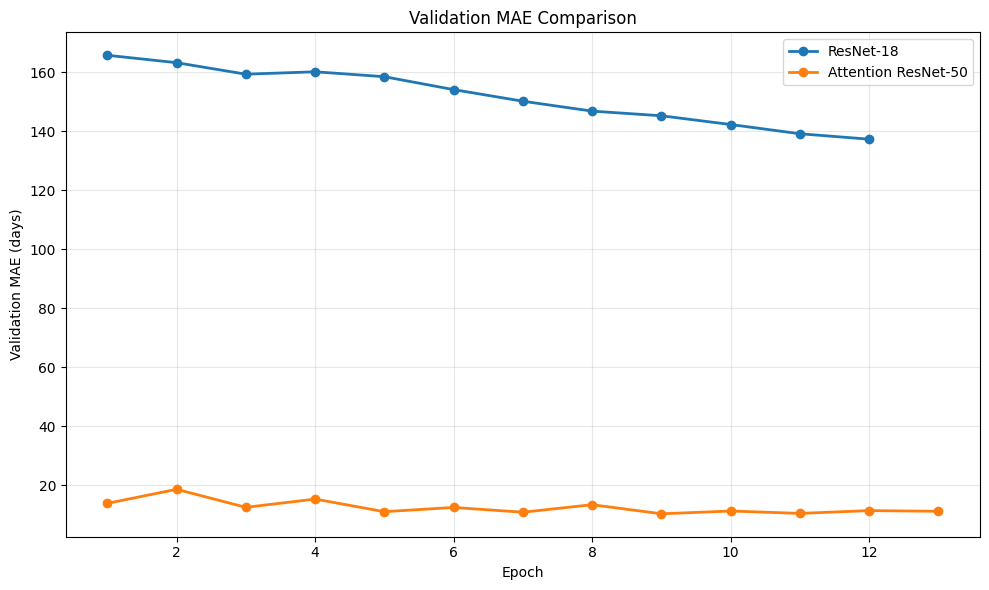

In [22]:

import matplotlib.pyplot as plt
from pathlib import Path

# Directory for saving graphs
FIGURES = RESULTS / "figures"
FIGURES.mkdir(exist_ok=True, parents=True)

# Combine training histories
histories = {
    "ResNet-18": h18,
    "Attention ResNet-50": ha
}

# Plot 1: Training Loss
plt.figure(figsize=(10, 6))

for name, hist in histories.items():
    plt.plot(
        hist["epoch"],
        hist["train_loss"],
        marker="o",
        linewidth=2,
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(FIGURES / "training_loss_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


# Plot 2: Validation MAE
plt.figure(figsize=(10, 6))

for name, hist in histories.items():
    plt.plot(
        hist["epoch"],
        hist["val_MAE"],
        marker="o",
        linewidth=2,
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation MAE (days)")
plt.title("Validation MAE Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(FIGURES / "validation_mae_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


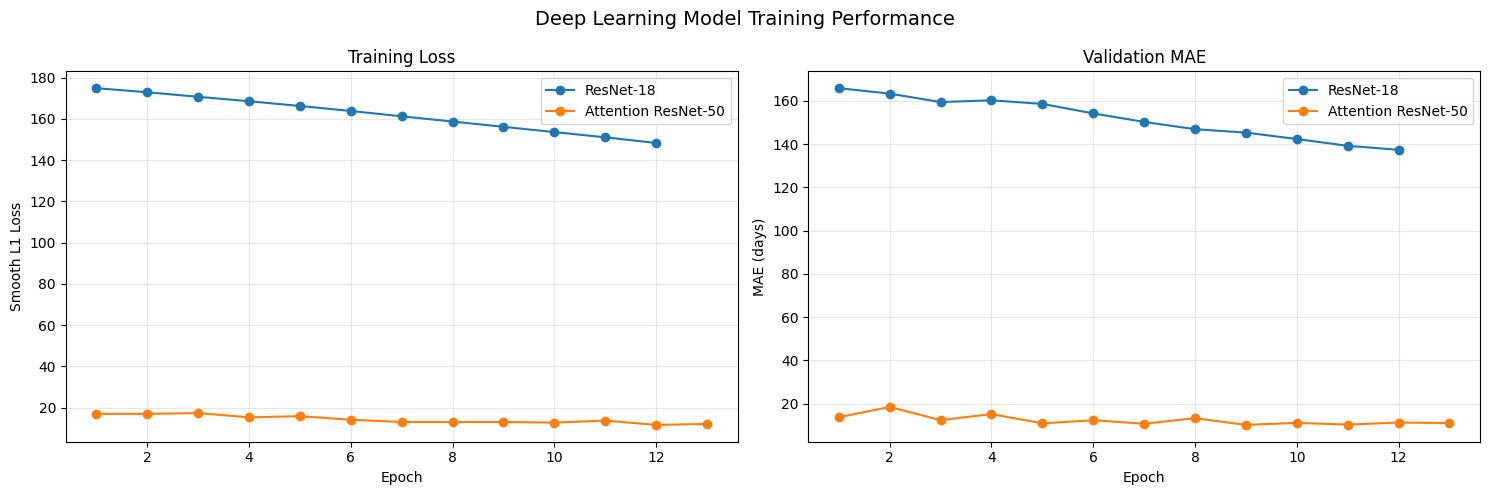

In [23]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, hist in histories.items():
    axes[0].plot(
        hist["epoch"], hist["train_loss"],
        marker="o", label=name
    )

    axes[1].plot(
        hist["epoch"], hist["val_MAE"],
        marker="o", label=name
    )

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Smooth L1 Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Validation MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MAE (days)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("Deep Learning Model Training Performance",
             fontsize=14)

plt.tight_layout()

plt.savefig(
    FIGURES / "deep_learning_training_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 15. Compare all five models and select using validation MAE

In [24]:
rows=[{"Model":n,**metrics(yv,p)} for n,p in val_preds.items()]
yy18,pp18=predict_dl(m18,val_loader); yya,ppa=predict_dl(matt,val_loader)
rows += [{"Model":"ResNet-18",**metrics(yy18,pp18)},
         {"Model":"Multi-Plane Attention ResNet-50",**metrics(yya,ppa)}]
comparison=pd.DataFrame(rows).sort_values("MAE_days")
display(comparison)
comparison.to_csv(RESULTS/"validation_model_comparison.csv",index=False)
selected=comparison.iloc[0]["Model"]
print("Selected model:",selected,"(lowest validation MAE; test data not used for selection)")

,Model,MAE_days,RMSE_days,R2,Lin_CCC,MAE_weeks
4,Multi-Plane Attention ResNet-50,10.256357,12.530924,0.880048,0.939865,1.465194
0,Linear Regression,19.519835,23.979700,0.560733,0.725440,2.788548
1,Random Forest,25.475162,28.736882,0.369158,0.442680,3.639309
2,SVR RBF,29.845836,34.551577,0.088037,0.246835,4.263691
3,ResNet-18,137.322922,143.670358,-14.767975,0.009570,19.617560


Selected model: Multi-Plane Attention ResNet-50 (lowest validation MAE; test data not used for selection)


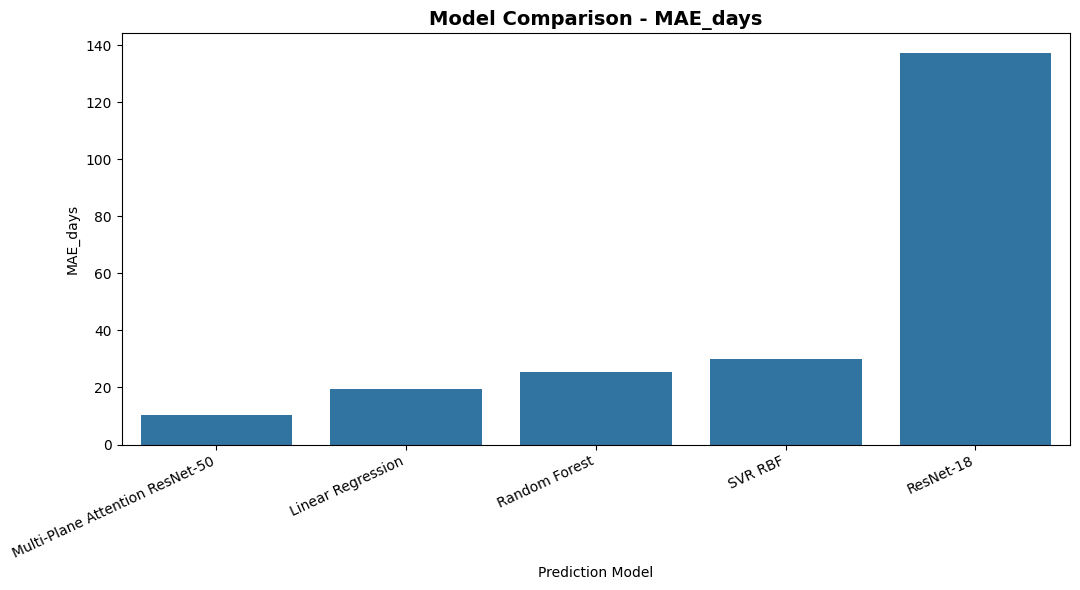

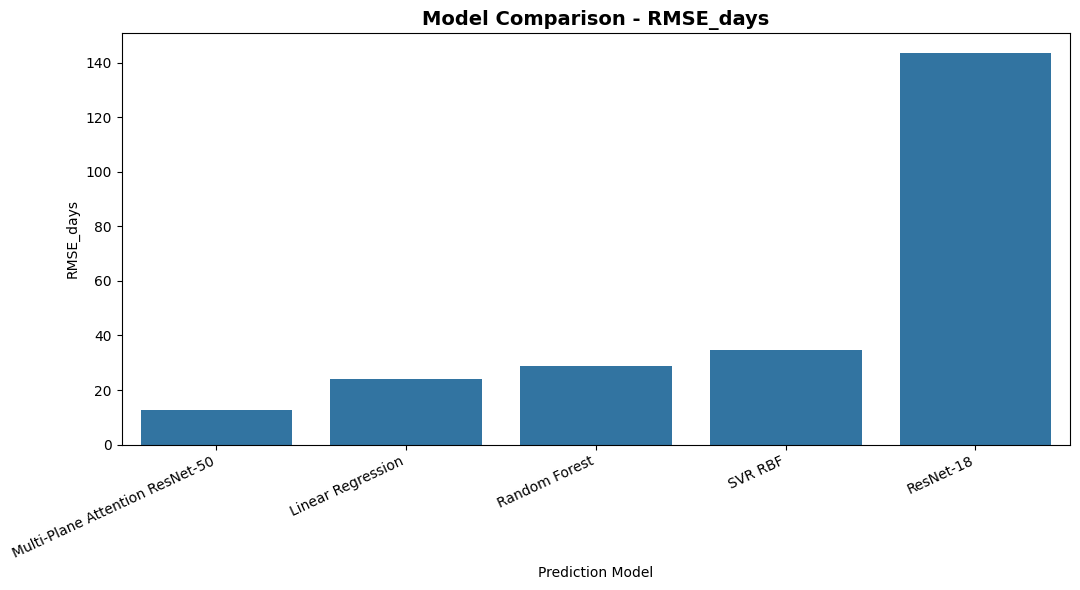

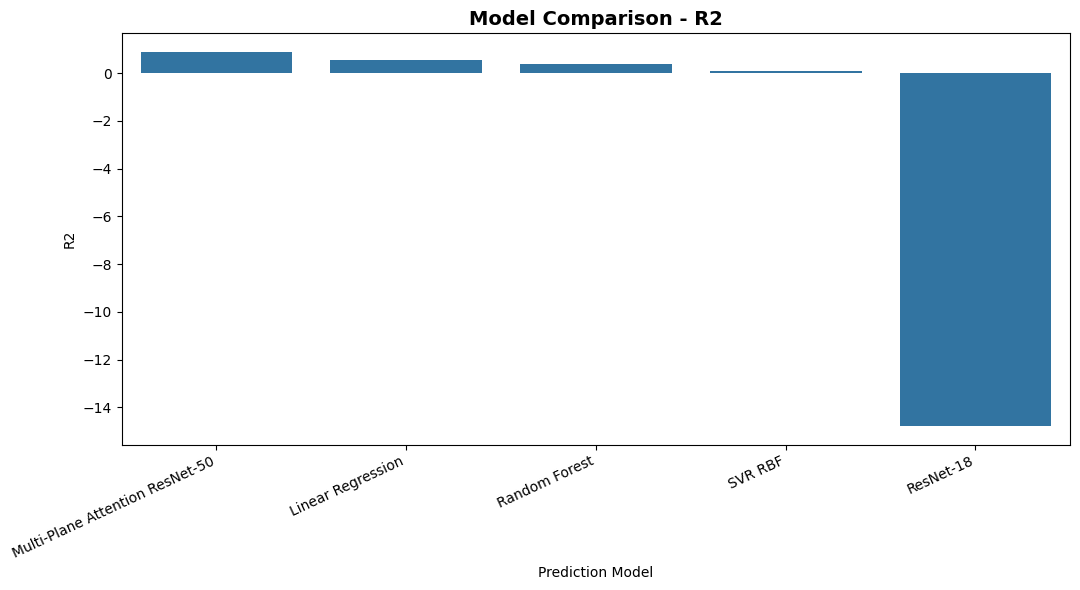

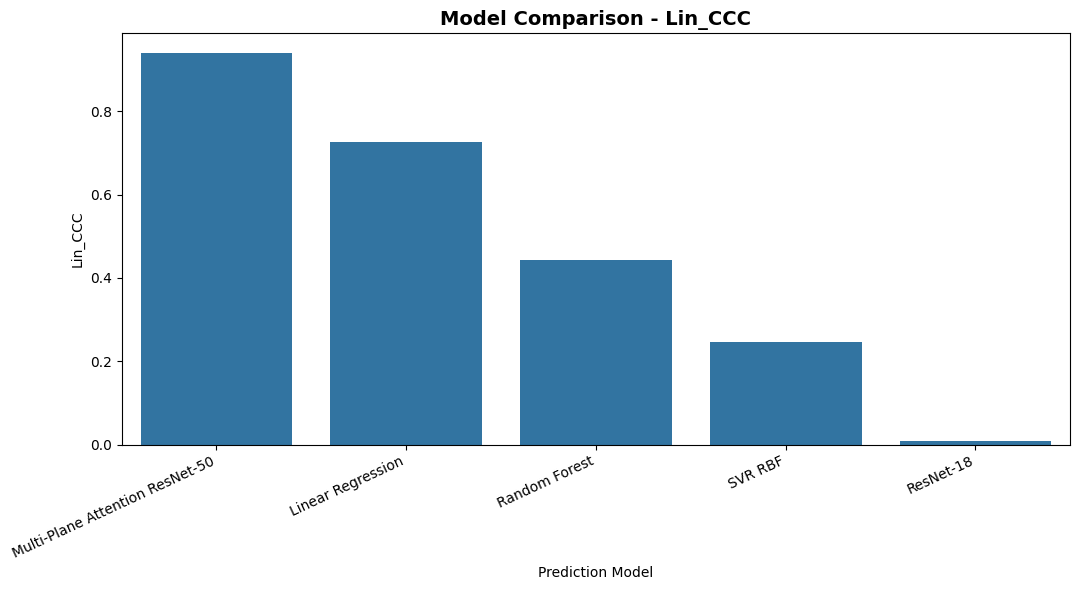

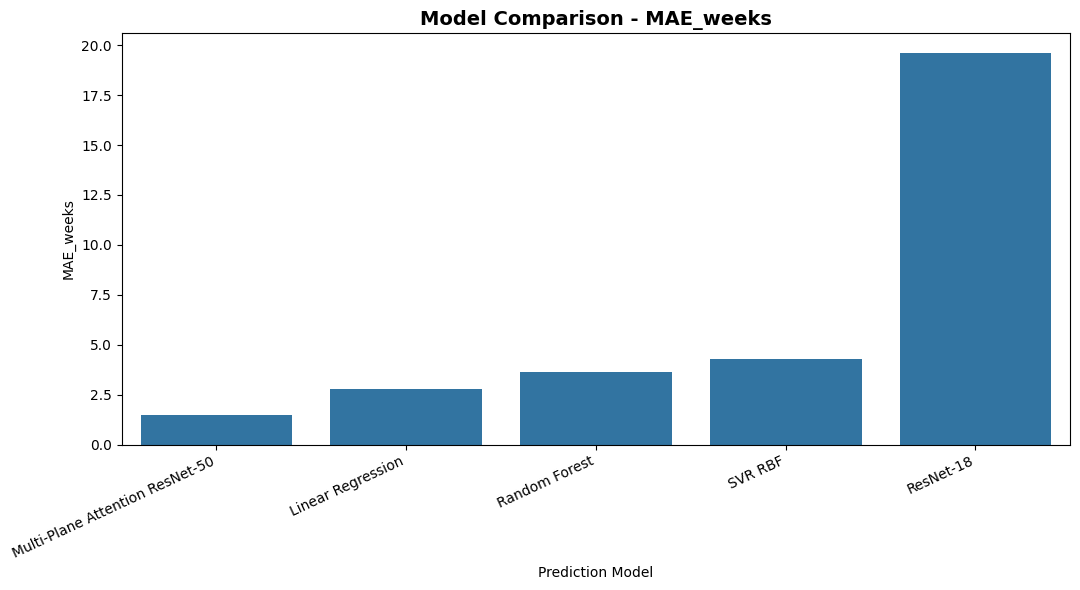

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics_to_plot = [
    "MAE_days",
    "RMSE_days",
    "R2",
    "Lin_CCC",
    "MAE_weeks"
]

for metric in metrics_to_plot:
    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=comparison,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}",
              fontsize=14, fontweight="bold")

    plt.xlabel("Prediction Model")
    plt.ylabel(metric)

    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()

    plt.savefig(
        RESULTS / f"model_comparison_{metric}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

##16. Fine-tuning the Selected Multi-Plane Attention ResNet-50

This section follows the model selection stage (Section 15). The Multi-Plane Attention ResNet-50 was selected because it achieved the lowest validation MAE of 10.256 days among the five evaluated models.

Fine-tuning is performed using the previously trained attention_resnet50.pt checkpoint. Rather than training a new model from scratch, the pretrained model is adapted using the training dataset to improve gestational-age prediction. The validation dataset is used to monitor improvement and select the best fine-tuned weights, while the test dataset remains untouched until final evaluation.

The objective is to reduce validation MAE without compromising the model's generalization performance.

###16.1 Load the existing checkpoint

The trained weights of the selected Multi-Plane Attention ResNet-50 are loaded from the saved checkpoint. This ensures that fine-tuning starts from the previously optimized model rather than random initialization. The checkpoint is retained as the baseline for comparison.




In [31]:
import torch
import torch.nn as nn
import numpy as np
import copy
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Checkpoint saved from the original model training
CHECKPOINT = RESULTS / "attention_resnet50.pt"

assert CHECKPOINT.exists(), f"Checkpoint not found: {CHECKPOINT}"

# Reconstruct the selected architecture
model_ft = MultiPlaneAttentionResNet50().to(DEVICE)

# Load the previously trained weights
state = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
    weights_only=True
)

model_ft.load_state_dict(state, strict=True)

print("Checkpoint loaded:", CHECKPOINT)
print("Fine-tuning model initialized successfully.")

Checkpoint loaded: /content/drive/MyDrive/fetal-gestational-age/results_fetal_ga/attention_resnet50.pt
Fine-tuning model initialized successfully.


###16.2 Evaluate the baseline before fine-tuning

Before fine-tuning, the selected model is evaluated on the validation set to establish its baseline performance. This result is used as the reference for determining whether fine-tuning provides a meaningful improvement.

In [32]:
def predict_dl(model, loader):
    model.eval()

    ys, ps = [], []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)

            pred = model(x)

            if isinstance(pred, tuple):
                pred = pred[0]

            ys.extend(y.cpu().numpy().reshape(-1))
            ps.extend(pred.cpu().numpy().reshape(-1))

    return np.asarray(ys), np.asarray(ps)


def regression_metrics(y_true, y_pred):
    return {
        "MAE_days": mean_absolute_error(y_true, y_pred),
        "RMSE_days": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAE_weeks": mean_absolute_error(y_true, y_pred) / 7
    }


# Evaluate original selected model
y_val, p_val = predict_dl(model_ft, val_loader)

baseline_metrics = regression_metrics(y_val, p_val)

print("Baseline Validation Performance")
for name, value in baseline_metrics.items():
    print(f"{name}: {value:.4f}")

Baseline Validation Performance
MAE_days: 10.2564
RMSE_days: 12.5309
R2: 0.8800
MAE_weeks: 1.4652


###16.3 Preserve the original model
The original trained weights are copied before fine-tuning. This allows the model to revert to the original checkpoint if the fine-tuning process does not produce better validation MAE. This safeguard prevents an inferior fine-tuned model from replacing the original selected model.

In [33]:
# Keep an independent copy of the original trained weights
baseline_state = {
    k: v.detach().cpu().clone()
    for k, v in model_ft.state_dict().items()
}

baseline_mae = baseline_metrics["MAE_days"]

# Initially, the original checkpoint remains the best model
best_state = copy.deepcopy(baseline_state)
best_mae = baseline_mae

print(f"Original validation MAE: {baseline_mae:.4f} days")

Original validation MAE: 10.2564 days


###16.4 Freeze the feature extraction encoder

During the initial fine-tuning experiment, the ResNet-50 encoder is frozen to retain the visual representations learned during the original training. Only the attention mechanism and regression head are updated.

This strategy reduces the number of trainable parameters and limits the risk of disrupting the pretrained feature representations, particularly when the training dataset is relatively small.

In [34]:
# Freeze the encoder
for param in model_ft.encoder.parameters():
    param.requires_grad = False

# Allow attention and regression head to learn
for param in model_ft.attn.parameters():
    param.requires_grad = True

for param in model_ft.head.parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel() for p in model_ft.parameters()
    if p.requires_grad
)

total_params = sum(p.numel() for p in model_ft.parameters())

print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable percentage: {100 * trainable_params / total_params:.2f}%")

Trainable parameters: 1,049,602
Total parameters: 24,557,634
Trainable percentage: 4.27%


###16.5 Configure the fine-tuning process

The model is fine-tuned using AdamW with a low learning rate of \(1 x 10^{-5}\) and Smooth L1 loss. A maximum of 30 epochs is allowed, with early stopping after seven consecutive epochs without validation improvement.

Validation MAE is used to select the best checkpoint. The original baseline weights remain the best weights unless a fine-tuned epoch achieves a lower validation MAE.

In [35]:
from torch.optim import AdamW

# Optimizer updates only trainable parameters
optimizer = AdamW(
    filter(lambda p: p.requires_grad, model_ft.parameters()),
    lr=1e-5,
    weight_decay=1e-4
)

criterion = nn.SmoothL1Loss()

MAX_EPOCHS = 30
PATIENCE = 7

history_ft = {
    "train_loss": [],
    "val_mae": []
}

epochs_without_improvement = 0

###16.6 Fine-tune the model
Fine-tuning is performed using the training set, while validation MAE is computed at the end of every epoch. The checkpoint with the lowest validation MAE is retained.

Early stopping is applied to prevent unnecessary training once the model stops improving. If no epoch outperforms the original model, the original weights are restored automatically.

In [36]:
for epoch in range(MAX_EPOCHS):

    # Training
    model_ft.train()

    # Keep frozen encoder in evaluation mode
    model_ft.encoder.eval()

    train_losses = []

    for x, y in train_loader:

        x = x.to(DEVICE)
        y = y.float().to(DEVICE).reshape(-1)

        optimizer.zero_grad()

        pred = model_ft(x).reshape(-1)

        loss = criterion(pred, y)

        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    # Validation
    y_val, p_val = predict_dl(model_ft, val_loader)

    val_mae = mean_absolute_error(y_val, p_val)
    train_loss = np.mean(train_losses)

    history_ft["train_loss"].append(train_loss)
    history_ft["val_mae"].append(val_mae)

    # Update best checkpoint only if it beats the previous best
    if val_mae < best_mae:

        best_mae = val_mae

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model_ft.state_dict().items()
        }

        epochs_without_improvement = 0

        print(
            f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val MAE: {val_mae:.4f} | "
            f"New best"
        )

    else:

        epochs_without_improvement += 1

        print(
            f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val MAE: {val_mae:.4f} | "
            f"No improvement ({epochs_without_improvement}/{PATIENCE})"
        )

    # Early stopping
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")

        break

# Restore the best weights (baseline if fine-tuning never improved)
model_ft.load_state_dict(best_state)

print("\nFine-tuning completed.")
print(f"Baseline Validation MAE: {baseline_mae:.4f} days")
print(f"Best Validation MAE:     {best_mae:.4f} days")
print(f"Improvement:             {baseline_mae - best_mae:.4f} days")

Epoch 01/30 | Train Loss: 11.0186 | Val MAE: 10.2155 | New best
Epoch 02/30 | Train Loss: 10.8369 | Val MAE: 10.2529 | No improvement (1/7)
Epoch 03/30 | Train Loss: 10.7610 | Val MAE: 10.2064 | New best
Epoch 04/30 | Train Loss: 10.7373 | Val MAE: 10.1884 | New best
Epoch 05/30 | Train Loss: 11.1446 | Val MAE: 10.1817 | New best
Epoch 06/30 | Train Loss: 11.4661 | Val MAE: 10.2229 | No improvement (1/7)
Epoch 07/30 | Train Loss: 10.9745 | Val MAE: 10.1774 | New best
Epoch 08/30 | Train Loss: 11.0319 | Val MAE: 10.2445 | No improvement (1/7)
Epoch 09/30 | Train Loss: 11.1221 | Val MAE: 10.3193 | No improvement (2/7)
Epoch 10/30 | Train Loss: 11.7585 | Val MAE: 10.1700 | New best
Epoch 11/30 | Train Loss: 11.3730 | Val MAE: 10.1771 | No improvement (1/7)
Epoch 12/30 | Train Loss: 11.2447 | Val MAE: 10.1884 | No improvement (2/7)
Epoch 13/30 | Train Loss: 10.9341 | Val MAE: 10.1697 | New best
Epoch 14/30 | Train Loss: 10.7393 | Val MAE: 10.1718 | No improvement (1/7)
Epoch 15/30 | Train 

###16.8 Visualize fine-tuning performance
The validation MAE across fine-tuning epochs is visualized to assess the model's learning behavior. The baseline validation MAE is included for comparison. This visualization helps identify whether fine-tuning improves prediction accuracy, stabilizes performance, or begins to overfit.

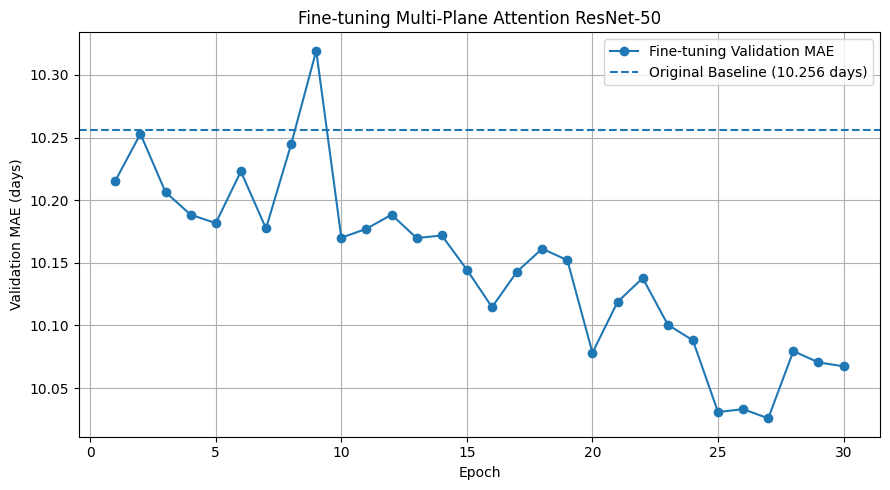

In [37]:
import matplotlib.pyplot as plt

epochs = range(1, len(history_ft["val_mae"]) + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    history_ft["val_mae"],
    marker="o",
    label="Fine-tuning Validation MAE"
)

plt.axhline(
    baseline_mae,
    linestyle="--",
    label=f"Original Baseline ({baseline_mae:.3f} days)"
)

plt.xlabel("Epoch")
plt.ylabel("Validation MAE (days)")
plt.title("Fine-tuning Multi-Plane Attention ResNet-50")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

###16.8 Save the best fine-tuned checkpoint
The best checkpoint is saved separately from the original model. The original attention_resnet50.pt is preserved to ensure that the baseline remains available for reproducibility and comparison.

In [38]:
# Save the best weights without overwriting the original model
FINETUNED_CHECKPOINT = RESULTS / "attention_resnet50_finetuned_best.pt"

torch.save(best_state, FINETUNED_CHECKPOINT)

print("Best checkpoint saved to:")
print(FINETUNED_CHECKPOINT)

Best checkpoint saved to:
/content/drive/MyDrive/fetal-gestational-age/results_fetal_ga/attention_resnet50_finetuned_best.pt


###16.9 Compare original and fine-tuned validation performance
The original and fine-tuned models are compared using validation MAE. Fine-tuning is considered beneficial if it reduces MAE relative to the original model. If no improvement is achieved, the baseline model is retained as the selected model.

In [39]:
# Evaluate the restored best model
y_val_ft, p_val_ft = predict_dl(model_ft, val_loader)

finetuned_metrics = regression_metrics(y_val_ft, p_val_ft)

comparison = {
    "Original": baseline_metrics,
    "Fine-tuned": finetuned_metrics
}

print("\nValidation Performance Comparison")
print("-" * 55)

for model_name, metrics in comparison.items():

    print(f"\n{model_name}")

    for metric, value in metrics.items():

        print(f"{metric}: {value:.4f}")

print("\nMAE improvement:",
      round(baseline_mae - finetuned_metrics["MAE_days"], 4),
      "days")


Validation Performance Comparison
-------------------------------------------------------

Original
MAE_days: 10.2564
RMSE_days: 12.5309
R2: 0.8800
MAE_weeks: 1.4652

Fine-tuned
MAE_days: 10.0258
RMSE_days: 12.3384
R2: 0.8837
MAE_weeks: 1.4323

MAE improvement: 0.2306 days


### 17 Final test evaluation
The selected fine-tuned Multi-Plane Attention ResNet-50 was evaluated on the independent test dataset to assess its generalization performance. The test dataset was not used during model training, fine-tuning, or validation-based checkpoint selection. MAE, RMSE, R², Lin's Concordance Correlation Coefficient (CCC), and MAE in weeks were calculated to evaluate prediction accuracy and agreement between predicted and actual gestational ages.

In [40]:
# Load the best fine-tuned checkpoint
FINAL_CHECKPOINT = RESULTS / "attention_resnet50_finetuned_best.pt"

final_model = MultiPlaneAttentionResNet50().to(DEVICE)

final_state = torch.load(
    FINAL_CHECKPOINT,
    map_location=DEVICE,
    weights_only=True
)

final_model.load_state_dict(final_state, strict=True)

# Evaluate once on the untouched test set
y_test, p_test = predict_dl(final_model, test_loader)

# Calculate metrics
test_metrics = regression_metrics(y_test, p_test)

# Lin's Concordance Correlation Coefficient
def lin_ccc(y_true, y_pred):
    mean_true = np.mean(y_true)
    mean_pred = np.mean(y_pred)

    var_true = np.var(y_true)
    var_pred = np.var(y_pred)

    covariance = np.mean(
        (y_true - mean_true) * (y_pred - mean_pred)
    )

    return (
        2 * covariance /
        (var_true + var_pred + (mean_true - mean_pred)**2)
    )

test_metrics["Lin_CCC"] = lin_ccc(y_test, p_test)

print("FINAL TEST PERFORMANCE")
print("-" * 45)

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("MAE in weeks:",
      f"{test_metrics['MAE_days'] / 7:.4f}")

FINAL TEST PERFORMANCE
---------------------------------------------
MAE_days: 9.3040
RMSE_days: 12.9625
R2: 0.8760
MAE_weeks: 1.3291
Lin_CCC: 0.9367
MAE in weeks: 1.3291


###17.2 Compare original and fine-tuned models on the test set

In [41]:
original_model = MultiPlaneAttentionResNet50().to(DEVICE)

original_state = torch.load(
    RESULTS / "attention_resnet50.pt",
    map_location=DEVICE,
    weights_only=True
)

original_model.load_state_dict(original_state, strict=True)

y_test_original, p_test_original = predict_dl(
    original_model, test_loader
)

original_test_metrics = regression_metrics(
    y_test_original, p_test_original
)

print("Original test MAE:",
      round(original_test_metrics["MAE_days"], 4))

print("Fine-tuned test MAE:",
      round(test_metrics["MAE_days"], 4))

Original test MAE: 9.748
Fine-tuned test MAE: 9.304


###18. Actual vs Predicted Gestational Age
This section evaluates the relationship between actual and predicted gestational age using the independent test dataset. A scatter plot is generated to visualize prediction accuracy and identify deviations from the ideal prediction line. Predictions closer to the diagonal reference line indicate stronger agreement between actual and predicted gestational age.

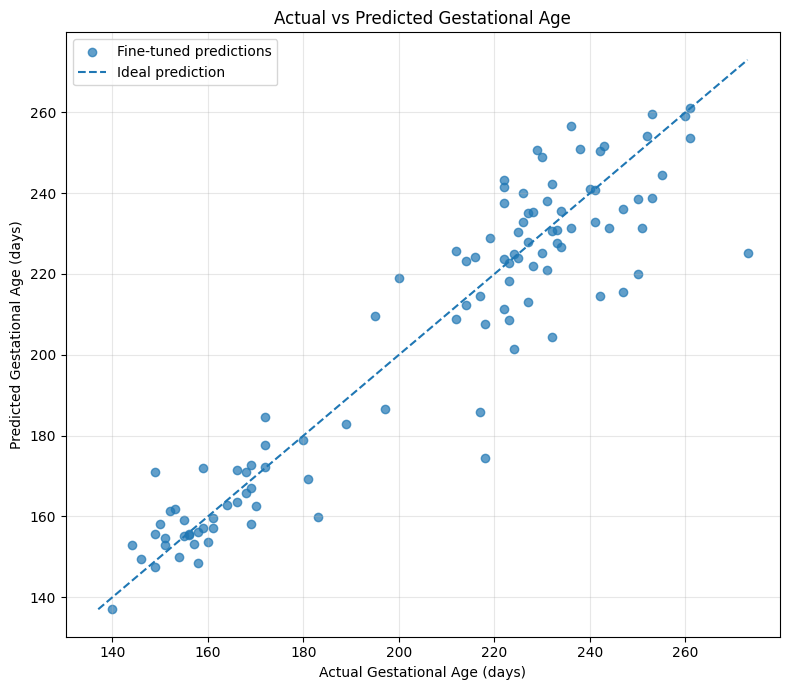

In [42]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 7))

plt.scatter(
    y_test,
    p_test,
    alpha=0.7,
    label="Fine-tuned predictions"
)

minimum = min(y_test.min(), p_test.min())
maximum = max(y_test.max(), p_test.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Ideal prediction"
)

plt.xlabel("Actual Gestational Age (days)")
plt.ylabel("Predicted Gestational Age (days)")
plt.title("Actual vs Predicted Gestational Age")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS / "actual_vs_predicted_finetuned.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

###19. Residual Error Analysis

Residual error analysis examines the differences between actual and predicted gestational age. Residuals are calculated as actual gestational age minus predicted gestational age. Their distribution is examined to identify systematic prediction errors, variability, and possible patterns across gestational ages.

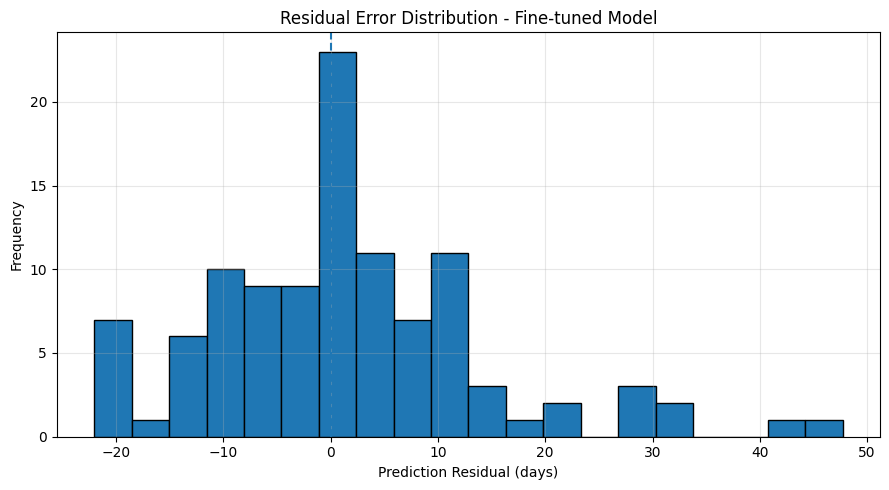

Mean residual: 1.506 days
Residual standard deviation: 12.875 days
Maximum absolute error: 47.717 days


In [43]:
residuals = y_test - p_test

plt.figure(figsize=(9, 5))

plt.hist(residuals, bins=20, edgecolor="black")

plt.axvline(0, linestyle="--")

plt.xlabel("Prediction Residual (days)")
plt.ylabel("Frequency")
plt.title("Residual Error Distribution - Fine-tuned Model")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTS / "residual_distribution_finetuned.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mean residual:", round(residuals.mean(), 3), "days")
print("Residual standard deviation:", round(residuals.std(), 3), "days")
print("Maximum absolute error:", round(np.abs(residuals).max(), 3), "days")

###20. Explainability Using Grad-CAM
Gradient-weighted Class Activation Mapping (Grad-CAM) is used to improve the interpretability of the fine-tuned Multi-Plane Attention ResNet-50. It generates visual heatmaps highlighting image regions that contribute to the model's gestational-age predictions.

In this study, Grad-CAM is applied to the three fetal brain MRI planes: axial, coronal and sagittal. The resulting heatmaps are overlaid on the original MRI slices to examine which regions influence the model's predictions.

Since this is a regression task rather than a classification task, gradients are calculated directly from the predicted gestational age.

##### Select a test MRI examination - A representative examination is selected from the independent test dataset for explainability analysis. The same three-plane MRI input used by the prediction model is retained to ensure that the visual explanation corresponds to the model's actual input.

##### Generate Grad-CAM heatmaps - Grad-CAM uses the gradients of the predicted gestational age with respect to the final convolutional feature maps of the ResNet-50 encoder. These gradients are used to calculate importance weights and generate a heatmap for each MRI plane. The heatmaps indicate image regions that have a stronger influence on the model's output.

In [44]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Use the selected fine-tuned model
final_model.eval()

# Select one examination from the test dataset
x, y = next(iter(test_loader))

# Use the first examination in the batch
x_sample = x[0:1].to(DEVICE)
actual_ga = y[0].item()

# Store activations from the three encoder passes
activations = []

def forward_hook(module, inputs, output):
    output.retain_grad()
    activations.append(output)

# Hook the final convolutional block (ResNet-50 layer4)
target_layer = final_model.encoder[7]

hook = target_layer.register_forward_hook(forward_hook)

# Forward pass with gradients enabled
final_model.zero_grad()
activations.clear()

prediction = final_model(x_sample)

# Backpropagate the predicted gestational age
prediction.backward()

# Calculate Grad-CAM for each MRI plane
grad_cams = []

for activation in activations:

    gradients = activation.grad

    # Average gradients across spatial dimensions
    weights = gradients.mean(dim=(2, 3), keepdim=True)

    # Weighted combination of feature maps
    cam = (weights * activation).sum(dim=1, keepdim=True)

    # Retain positive contributions
    cam = F.relu(cam)

    # Resize heatmap to original input dimensions
    cam = F.interpolate(
        cam,
        size=x_sample.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    # Normalize between 0 and 1
    cam = cam.squeeze().detach().cpu().numpy()

    if cam.max() > cam.min():
        cam = (cam - cam.min()) / (cam.max() - cam.min())
    else:
        cam = np.zeros_like(cam)

    grad_cams.append(cam)

# Remove hook
hook.remove()

print(f"Actual GA: {actual_ga:.2f} days")
print(f"Predicted GA: {prediction.item():.2f} days")

Actual GA: 156.00 days
Predicted GA: 155.58 days


### 20.2. Visualize the three MRI planes
The Grad-CAM heatmaps are overlaid on the corresponding axial, coronal and sagittal MRI slices. This visualization allows examination of the spatial regions that contribute to the predicted gestational age. The heatmaps provide model-based explanations and should not be interpreted as definitive anatomical evidence or clinical localization.

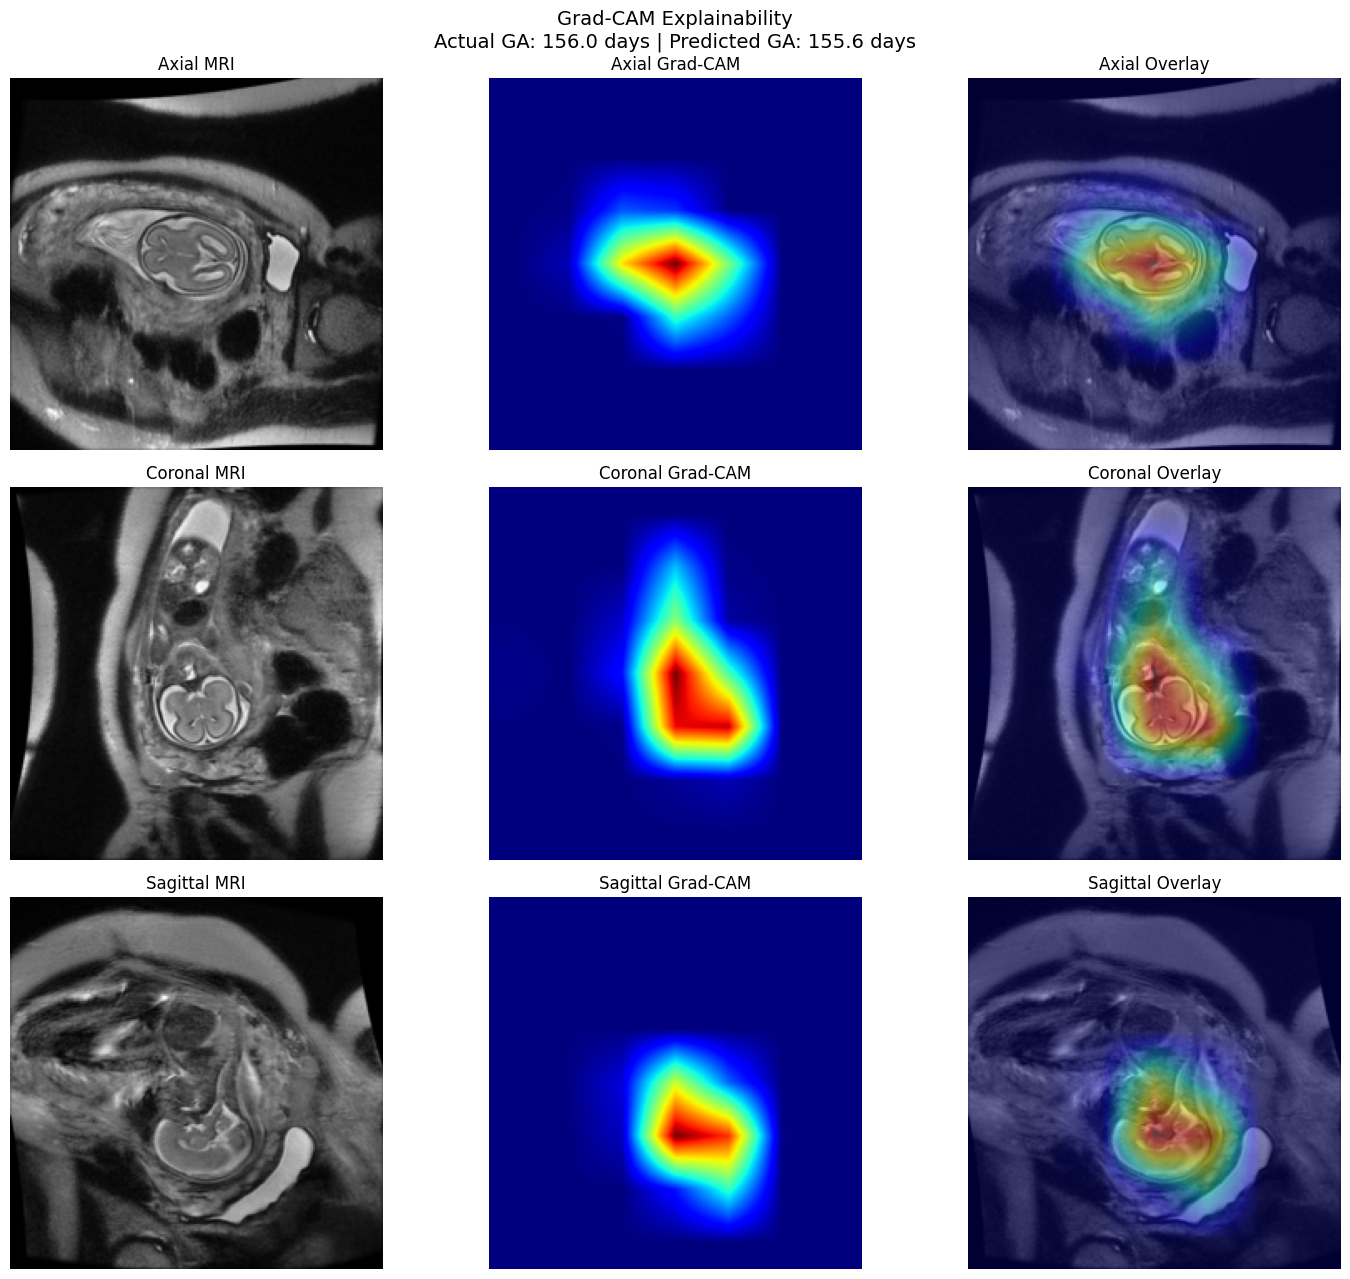

In [45]:
plane_names = ["Axial", "Coronal", "Sagittal"]

fig, axes = plt.subplots(3, 3, figsize=(15, 13))

for i in range(3):

    # Original MRI slice
    image = x_sample[0, i].detach().cpu().numpy()

    # Normalize for display only
    image_display = (
        (image - image.min()) /
        (image.max() - image.min() + 1e-8)
    )

    # Grad-CAM heatmap
    cam = grad_cams[i]

    # Original image
    axes[i, 0].imshow(image_display, cmap="gray")
    axes[i, 0].set_title(f"{plane_names[i]} MRI")

    # Heatmap
    axes[i, 1].imshow(cam, cmap="jet")
    axes[i, 1].set_title(f"{plane_names[i]} Grad-CAM")

    # Overlay
    axes[i, 2].imshow(image_display, cmap="gray")
    axes[i, 2].imshow(cam, cmap="jet", alpha=0.4)
    axes[i, 2].set_title(f"{plane_names[i]} Overlay")

    for j in range(3):
        axes[i, j].axis("off")

fig.suptitle(
    f"Grad-CAM Explainability\n"
    f"Actual GA: {actual_ga:.1f} days | "
    f"Predicted GA: {prediction.item():.1f} days",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    RESULTS / "gradcam_three_plane_explainability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 20.3. Compare attention weights across MRI planes
Your architecture also has a learned attention mechanism that assigns weights to the three MRI planes. These weights complement Grad-CAM by showing how much the model relies on each plane when combining their extracted features.

The model's attention weights are examined to determine the relative contribution assigned to the axial, coronal and sagittal MRI planes. These weights provide a complementary view of the model's decision process, although they do not independently establish anatomical importance.

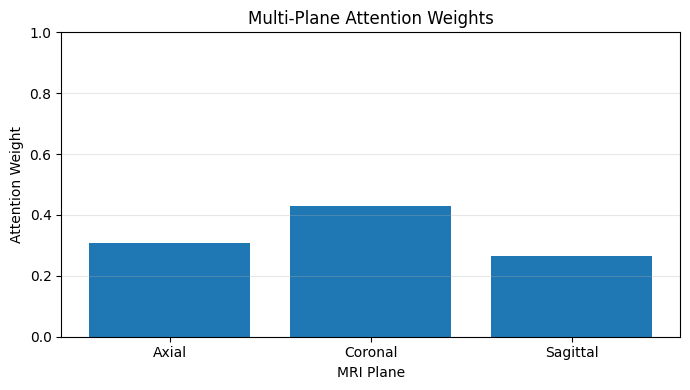

Attention weights: [0.30645335 0.42831483 0.26523182]
Sum of attention weights: 1.0


In [46]:
final_model.eval()

with torch.no_grad():
    pred, attention_weights = final_model(
        x_sample,
        return_attention=True
    )

weights = attention_weights[0].cpu().numpy()

plt.figure(figsize=(7, 4))

plt.bar(
    ["Axial", "Coronal", "Sagittal"],
    weights
)

plt.ylabel("Attention Weight")
plt.xlabel("MRI Plane")
plt.title("Multi-Plane Attention Weights")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTS / "attention_weights_three_planes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Attention weights:", weights)
print("Sum of attention weights:", weights.sum())

#### 20.4. Explainability findings
Grad-CAM was applied to the fine-tuned Multi-Plane Attention ResNet-50 to investigate the image regions influencing gestational-age predictions. Separate heatmaps were generated for the axial, coronal and sagittal MRI planes. The learned attention weights were also examined to assess the relative contribution of each plane to the model's prediction. These visual explanations provide additional insight into the model's behavior and support the interpretability of its predictions.

### 21A. Gestational-Age-Band Error Stratification
This analysis evaluates the prediction error of the final model across different gestational-age groups. Mean Absolute Error (MAE) is calculated for each group to determine whether prediction performance varies with gestational age.

Prediction Error by Gestational-Age Band


,GA_band,Sample_Size,MAE_days,SD_Error_days,Median_Error_days
0,<24 weeks,27,5.084,4.770,3.773
1,24–28 weeks,14,7.476,6.442,5.933
2,28–32 weeks,20,12.541,10.682,10.433
3,32–36 weeks,38,10.872,8.805,8.309
4,36–45 weeks,8,11.206,15.535,7.056


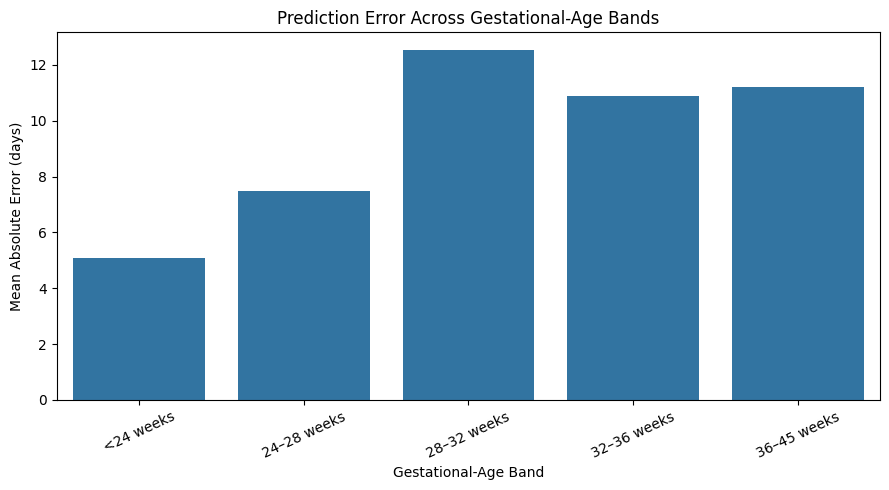


Gestational-age-band analysis completed.


In [51]:
# Create a DataFrame using final held-out test predictions
ga_analysis = pd.DataFrame({
    "Actual_GA_days": np.asarray(y_test).reshape(-1),
    "Predicted_GA_days": np.asarray(p_test).reshape(-1)
})

# Calculate absolute prediction error
ga_analysis["Absolute_Error_days"] = np.abs(
    ga_analysis["Actual_GA_days"] -
    ga_analysis["Predicted_GA_days"]
)

# Define gestational-age bands
ga_bins = [0, 168, 196, 224, 252, 315]

ga_labels = [
    "<24 weeks",
    "24–28 weeks",
    "28–32 weeks",
    "32–36 weeks",
    "36–45 weeks"
]

ga_analysis["GA_band"] = pd.cut(
    ga_analysis["Actual_GA_days"],
    bins=ga_bins,
    labels=ga_labels,
    right=False
)

# Calculate performance metrics for each band
ga_report = (
    ga_analysis
    .groupby("GA_band", observed=False)
    .agg(
        Sample_Size=("Absolute_Error_days", "count"),
        MAE_days=("Absolute_Error_days", "mean"),
        SD_Error_days=("Absolute_Error_days", "std"),
        Median_Error_days=("Absolute_Error_days", "median")
    )
    .reset_index()
    .rename(columns={"GA_band": "GA_band"})
)

# Remove bands without test samples
ga_report = ga_report.dropna(subset=["MAE_days"])

# Display results
print("Prediction Error by Gestational-Age Band")
display(ga_report.round(3))

# Save results
ga_report.to_csv(
    RESULTS / "GA_band_error_analysis.csv",
    index=False
)

# Plot MAE by gestational-age band
plt.figure(figsize=(9, 5))

sns.barplot(
    data=ga_report,
    x="GA_band",
    y="MAE_days"
)

plt.xlabel("Gestational-Age Band")
plt.ylabel("Mean Absolute Error (days)")
plt.title("Prediction Error Across Gestational-Age Bands")
plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig(
    RESULTS / "error_by_GA_band.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nGestational-age-band analysis completed.")


### 21B. Bootstrap Confidence Intervals for Gestational-Age-Band MAE
Bootstrap resampling is used to estimate 95% confidence intervals for the Mean Absolute Error (MAE) within each gestational-age band. This analysis provides an indication of the uncertainty associated with the model's prediction errors across different gestational-age ranges.

Bootstrap 95% Confidence Intervals for GA-Band MAE


,GA_band,Sample_Size,MAE_days,CI_lower,CI_upper
0,<24 weeks,27,5.084,3.442,7.024
1,24–28 weeks,14,7.476,4.402,10.906
2,28–32 weeks,20,12.541,8.308,17.339
3,32–36 weeks,38,10.872,8.239,13.756
4,36–45 weeks,8,11.206,3.471,22.664


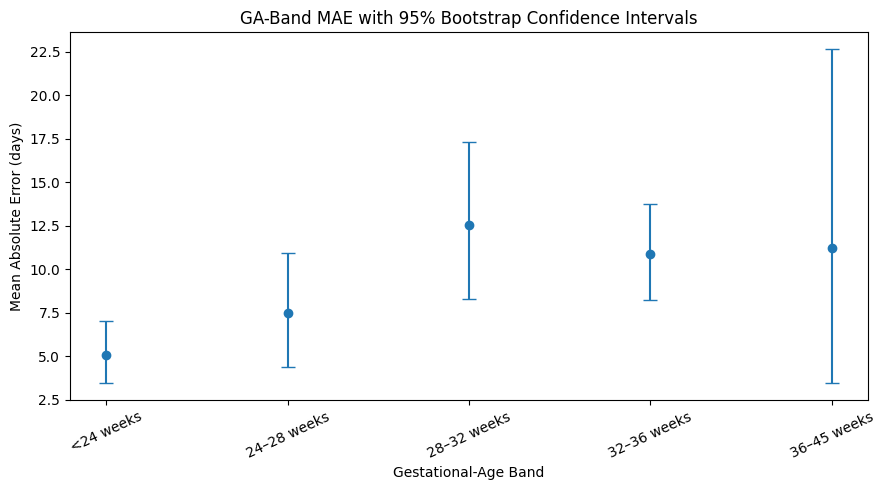


Bootstrap confidence interval analysis completed.
Bootstrap repetitions: 10000
Confidence level: 95%


In [52]:
# Set bootstrap parameters
N_BOOTSTRAPS = 10000
CONFIDENCE_LEVEL = 0.95
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

bootstrap_results = []

# Calculate bootstrap confidence intervals for each GA band
for band in ga_labels:

    # Select absolute errors for the current gestational-age band
    errors = ga_analysis.loc[
        ga_analysis["GA_band"] == band,
        "Absolute_Error_days"
    ].dropna().to_numpy()

    n = len(errors)

    # Skip bands without test samples
    if n == 0:
        continue

    # Original sample MAE
    observed_mae = np.mean(errors)

    # Bootstrap resampling with replacement
    bootstrap_maes = np.empty(N_BOOTSTRAPS)

    for i in range(N_BOOTSTRAPS):

        resampled_errors = rng.choice(
            errors,
            size=n,
            replace=True
        )

        bootstrap_maes[i] = np.mean(resampled_errors)

    # Calculate percentile confidence interval
    alpha = 1 - CONFIDENCE_LEVEL

    lower_ci = np.percentile(
        bootstrap_maes,
        100 * alpha / 2
    )

    upper_ci = np.percentile(
        bootstrap_maes,
        100 * (1 - alpha / 2)
    )

    bootstrap_results.append({
        "GA_band": band,
        "Sample_Size": n,
        "MAE_days": observed_mae,
        "CI_lower": lower_ci,
        "CI_upper": upper_ci
    })

# Create results DataFrame
bootstrap_report = pd.DataFrame(bootstrap_results)

# Display results
print("Bootstrap 95% Confidence Intervals for GA-Band MAE")
display(bootstrap_report.round(3))

# Save results
bootstrap_report.to_csv(
    RESULTS / "GA_band_bootstrap_CI.csv",
    index=False
)

# Plot MAE with 95% confidence intervals
plt.figure(figsize=(9, 5))

x = np.arange(len(bootstrap_report))

plt.errorbar(
    x,
    bootstrap_report["MAE_days"],
    yerr=[
        bootstrap_report["MAE_days"] - bootstrap_report["CI_lower"],
        bootstrap_report["CI_upper"] - bootstrap_report["MAE_days"]
    ],
    fmt="o",
    capsize=5
)

plt.xticks(
    x,
    bootstrap_report["GA_band"],
    rotation=25
)

plt.xlabel("Gestational-Age Band")
plt.ylabel("Mean Absolute Error (days)")
plt.title("GA-Band MAE with 95% Bootstrap Confidence Intervals")

plt.tight_layout()

plt.savefig(
    RESULTS / "GA_band_bootstrap_CI.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nBootstrap confidence interval analysis completed.")
print(f"Bootstrap repetitions: {N_BOOTSTRAPS}")
print(f"Confidence level: {CONFIDENCE_LEVEL * 100:.0f}%")


###22. Attention Weight Inspection
This analysis examines how the selected Multi-Plane Attention ResNet-50 model distributes attention across the axial, coronal, and sagittal MRI planes. Attention weights are extracted from the held-out test dataset to assess the relative contribution assigned to each plane during gestational-age prediction.

Attention Weight Descriptive Statistics


,Axial,Coronal,Sagittal
count,107.0000,107.0000,107.0000
mean,0.3568,0.3273,0.3159
std,0.1682,0.1339,0.1236
min,0.0039,0.0001,0.0000
25%,0.2767,0.2868,0.2719
50%,0.3339,0.3551,0.3292
75%,0.4429,0.4105,0.3811
max,0.9939,0.5971,0.6048



Attention-weight verification:
Mean sum: 1.000000
Minimum sum: 1.000000
Maximum sum: 1.000000

Mean attention weight by MRI plane:


,Mean Attention Weight
Axial,0.3568
Coronal,0.3273
Sagittal,0.3159


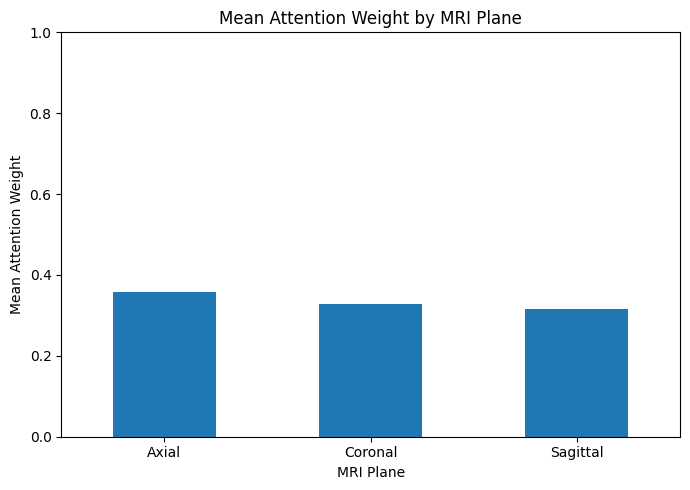


Attention analysis completed.
Results saved in: /content/drive/MyDrive/fetal-gestational-age/results_fetal_ga


In [50]:
if selected == "Multi-Plane Attention ResNet-50":

    # Use the final selected (fine-tuned) model
    final_model.eval()

    attention_weights = []

    # Extract attention weights without updating model parameters
    with torch.no_grad():
        for x, y in test_loader:

            x = x.to(DEVICE)

            _, weights = final_model(
                x,
                return_attention=True
            )

            attention_weights.extend(
                weights.cpu().numpy()
            )

    # Convert attention weights into a DataFrame
    attention_df = pd.DataFrame(
        attention_weights,
        columns=["Axial", "Coronal", "Sagittal"]
    )

    # Display descriptive statistics
    print("Attention Weight Descriptive Statistics")
    display(attention_df.describe().round(4))

    # Verify that weights sum to approximately 1 for each sample
    weight_sums = attention_df.sum(axis=1)

    print("\nAttention-weight verification:")
    print(f"Mean sum: {weight_sums.mean():.6f}")
    print(f"Minimum sum: {weight_sums.min():.6f}")
    print(f"Maximum sum: {weight_sums.max():.6f}")

    assert np.allclose(
        weight_sums.values,
        1.0,
        atol=1e-5
    ), "Attention weights do not sum to approximately 1."

    # Calculate mean attention weight for each MRI plane
    mean_attention = attention_df.mean()

    print("\nMean attention weight by MRI plane:")
    display(
        mean_attention.rename("Mean Attention Weight")
        .to_frame()
        .round(4)
    )

    # Save individual attention weights
    attention_df.to_csv(
        RESULTS / "attention_weights.csv",
        index=False
    )

    # Plot mean attention weights
    plt.figure(figsize=(7, 5))

    mean_attention.plot(
        kind="bar",
        ylim=(0, 1),
        rot=0
    )

    plt.title("Mean Attention Weight by MRI Plane")
    plt.xlabel("MRI Plane")
    plt.ylabel("Mean Attention Weight")
    plt.tight_layout()

    plt.savefig(
        RESULTS / "attention_weights.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("\nAttention analysis completed.")
    print(f"Results saved in: {RESULTS}")

else:
    print("Attention inspection is applicable only to "
          "Multi-Plane Attention ResNet-50.")


### 23. Save run metadata and final research checklist

In [54]:
import json
from datetime import datetime, timezone

info = {
    "experiment_date_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED,
    "device": str(DEVICE),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,

    "training_epochs": {
        "resnet18": EPOCHS_RESNET18,
        "attention_resnet50": EPOCHS_ATTENTION
    },

    "dataset_split": {
        "training_samples": len(train_df),
        "validation_samples": len(val_df),
        "test_samples": len(test_df)
    },

    "selected_model": selected,
    "final_checkpoint": "attention_resnet50_finetuned_best.pt",
    "selection_rule": "Minimum validation MAE",

    "test_metrics": {
        key: float(value)
        for key, value in test_metrics.items()
    },

    "evaluation": [
        "Final held-out test evaluation",
        "Grad-CAM explainability",
        "Gestational-age-band error stratification",
        "Bootstrap confidence intervals",
        "Attention weight inspection"
    ],

    "attention_architecture": (
        "Multi-plane attention ResNet-50; "
        "three 2D MRI planes used as separate inputs"
    )
}

# Save metadata
metadata_path = RESULTS / "run_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(info, f, indent=2)

print("Run metadata saved successfully:")
print(metadata_path.resolve())

# List generated research outputs
print("\nFINAL RESULTS DIRECTORY")

for p in sorted(RESULTS.iterdir()):
    if p.is_file():
        print(f"{p.name:<45} {p.stat().st_size / 1024:.2f} KB")


Run metadata saved successfully:
/content/drive/MyDrive/fetal-gestational-age/results_fetal_ga/run_metadata.json

FINAL RESULTS DIRECTORY
GA_band_bootstrap_CI.csv                      0.35 KB
GA_band_bootstrap_CI.png                      145.83 KB
GA_band_error_analysis.csv                    0.28 KB
actual_vs_predicted_finetuned.png             287.31 KB
attention_resnet50.pt                         96245.80 KB
attention_resnet50_finetuned.pt               96238.55 KB
attention_resnet50_finetuned_best.pt          96240.17 KB
attention_resnet50_verified.pt                96248.78 KB
attention_weights.csv                         3.42 KB
attention_weights.png                         72.11 KB
attention_weights_three_planes.png            61.87 KB
error_by_GA_band.png                          126.05 KB
gradcam_three_plane_explainability.png        844.89 KB
model_comparison_Lin_CCC.png                  155.96 KB
model_comparison_MAE_days.png                 164.30 KB
model_comparison_MAE_w